# EDA — VisDrone2019-DET splits

Exploratory check that the official VisDrone2019-DET **train / val / test-dev**
splits are stratified (same class mix and object-size mix everywhere) and a
visual look at representative photos. All statistics are computed in
**original-image coordinates** from the converted YOLO labels.


## 0. Setup


In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = ROOT / "data"
IMAGES_DIR = DATA_DIR / "images"
LABELS_DIR = DATA_DIR / "labels"
IGNORE_DIR = DATA_DIR / "ignore"
MANIFESTS_DIR = DATA_DIR / "manifests"

CLASSES = [
    "pedestrian",
    "people",
    "bicycle",
    "car",
    "van",
    "truck",
    "tricycle",
    "awning-tricycle",
    "bus",
    "motor",
]
SPLITS = ["train", "val", "test"]
TINY_AREA = 16**2  # < 256 px^2
SMALL_AREA = 32**2  # < 1024 px^2
MEDIUM_AREA = 96**2  # < 9216 px^2
SIZE_BUCKETS = ["tiny", "small", "medium", "large"]
COLORS = plt.cm.tab10(np.linspace(0, 1, len(CLASSES)))
COLOR_BY_CLASS = dict(enumerate(COLORS))

manifests = {split: pd.read_csv(MANIFESTS_DIR / f"{split}.csv") for split in SPLITS}
print({split: len(df) for split, df in manifests.items()})

{'train': 6471, 'val': 548, 'test': 1610}


## 1. Per-split overview


In [2]:
overview = pd.DataFrame(
    {
        "images": [len(manifests[s]) for s in SPLITS],
        "objects": [int(manifests[s]["n_boxes"].sum()) for s in SPLITS],
        "ignored regions": [int(manifests[s]["n_ignored"].sum()) for s in SPLITS],
        "objects/image": [manifests[s]["n_boxes"].mean() for s in SPLITS],
        "ignored/image": [manifests[s]["n_ignored"].mean() for s in SPLITS],
    },
    index=SPLITS,
)
display(overview.round(2))

,images,objects,ignored regions,objects/image,ignored/image
train,6471,343197,10345,53.04,1.60
val,548,38759,1410,70.73,2.57
test,1610,75101,2445,46.65,1.52


## 2. Object table (all boxes in original coordinates)


In [4]:
def load_split_boxes(split: str) -> pd.DataFrame:
    """All ground-truth boxes of a split with pixel geometry and area."""
    cls_ids: list[int] = []
    widths: list[float] = []
    heights: list[float] = []
    images: list[str] = []
    for row in manifests[split].itertuples(index=False):
        label_path = LABELS_DIR / split / f"{Path(row.image).stem}.txt"
        if not label_path.exists():
            continue
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            cls_ids.append(int(parts[0]))
            widths.append(float(parts[3]) * row.width)
            heights.append(float(parts[4]) * row.height)
            images.append(row.image)
    return pd.DataFrame(
        {
            "split": split,
            "image": images,
            "class_id": cls_ids,
            "w": widths,
            "h": heights,
        }
    )


boxes = pd.concat([load_split_boxes(s) for s in SPLITS], ignore_index=True)
boxes["class"] = boxes["class_id"].map(dict(enumerate(CLASSES)))
boxes["area"] = boxes["w"] * boxes["h"]
boxes["size_bucket"] = np.select(
    [boxes["area"] < TINY_AREA, boxes["area"] < SMALL_AREA, boxes["area"] < MEDIUM_AREA],
    ["tiny", "small", "medium"],
    default="large",
)
print(f"{len(boxes):,} boxes loaded")
display(boxes.head())

457,057 boxes loaded


,split,image,class_id,w,h,class,area,size_bucket
0,train,0000002_00005_d_0000014.jpg,3,73.99968,32.99994,car,2441.98500,medium
1,train,0000002_00005_d_0000014.jpg,3,61.00032,45.99990,car,2806.00862,medium
2,train,0000002_00005_d_0000014.jpg,3,64.00032,50.99976,car,3264.00096,medium
3,train,0000002_00005_d_0000014.jpg,3,61.00032,37.99980,car,2317.99996,medium
4,train,0000002_00005_d_0000014.jpg,3,64.99968,32.99994,car,2144.98554,medium


## 3. Stratification check — class mix

If the splits were built by a stratified split, every split should have
approximately the same class proportions as the whole dataset. The tables below
report absolute counts, per-split proportions, and the **total variation
distance (TVD)** of each split's class proportions from the pooled proportions
(0 = identical, 1 = disjoint).


split,train,val,test
class,,,
pedestrian,79337,8844,21006
people,27056,5125,6376
bicycle,10479,1287,1302
car,144864,14064,28073
van,24956,1975,5771
truck,12875,750,2659
tricycle,4812,1045,530
awning-tricycle,3246,532,599
bus,5926,251,2940


split,train,val,test
class,,,
pedestrian,0.2312,0.2282,0.2797
people,0.0788,0.1322,0.0849
bicycle,0.0305,0.0332,0.0173
car,0.4221,0.3629,0.3738
van,0.0727,0.0510,0.0768
truck,0.0375,0.0194,0.0354
tricycle,0.0140,0.0270,0.0071
awning-tricycle,0.0095,0.0137,0.0080
bus,0.0173,0.0065,0.0391


split,share - pooled (train),share - pooled (val),share - pooled (test)
class,,,
pedestrian,-0.0077,-0.0107,0.0408
people,-0.0055,0.0479,0.0005
bicycle,0.0019,0.0046,-0.0113
car,0.0130,-0.0463,-0.0353
van,0.0012,-0.0206,0.0053
truck,0.0019,-0.0163,-0.0002
tricycle,0.0000,0.0130,-0.0069
awning-tricycle,-0.0001,0.0041,-0.0016
bus,-0.0027,-0.0135,0.0192


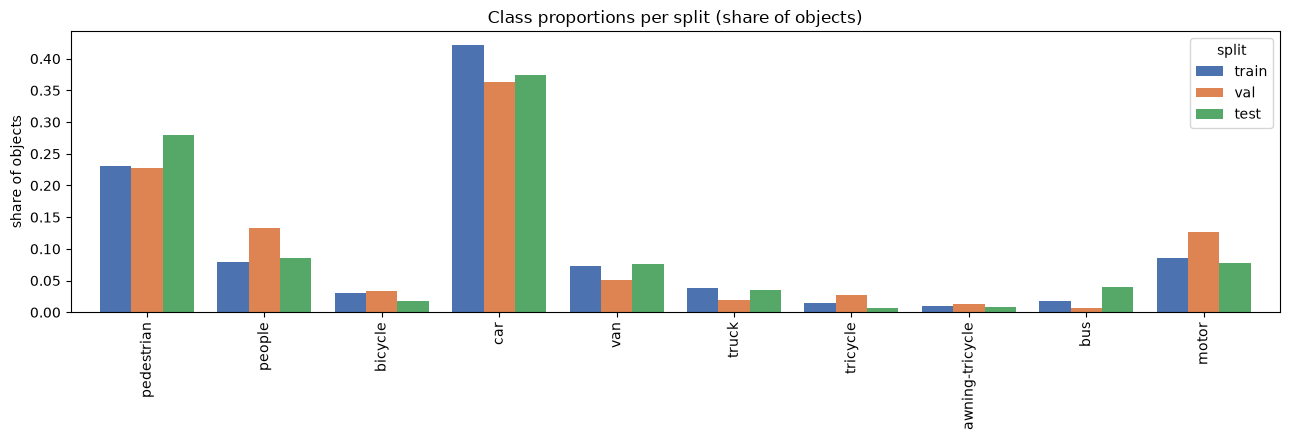

In [5]:
class_counts = pd.crosstab(boxes["class"], boxes["split"]).reindex(CLASSES)[SPLITS]
class_share = class_counts / class_counts.sum(axis=0)
class_pooled = class_counts.sum(axis=1) / class_counts.values.sum()
display(class_counts)
display(class_share.round(4))
display(
    class_share.sub(class_pooled, axis=0).round(4).rename(columns=lambda c: f"share - pooled ({c})")
)

ax = class_share.plot(
    kind="bar",
    figsize=(13, 4.5),
    color=["#4C72B0", "#DD8452", "#55A868"],
    width=0.8,
)
ax.set_title("Class proportions per split (share of objects)")
ax.set_ylabel("share of objects")
ax.set_xlabel("")
ax.legend(title="split")
plt.tight_layout()
plt.show()

### Class-mix verdict

We measure the **total variation distance (TVD, 0 = identical, 1 = disjoint)**
of each split against the pooled mix and against the training mix (the
distribution the model learns), then list the largest per-class gaps.


In [6]:
def tvd(share_a: pd.Series, share_b: pd.Series) -> float:
    """Total variation distance between two proportion vectors."""
    return float(0.5 * (share_a - share_b).abs().sum())


class_verdict = pd.DataFrame(
    {
        "class_TVD_vs_train": [tvd(class_share[s], class_share["train"]) for s in SPLITS],
        "class_TVD_vs_pooled": [tvd(class_share[s], class_pooled) for s in SPLITS],
    },
    index=SPLITS,
)
display(class_verdict.round(4))

for split in ("val", "test"):
    gap = (class_share[split] - class_share["train"]) * 100
    top = gap.abs().sort_values(ascending=False).head(4).index
    print(f"{split} vs train, largest class-share gaps (percentage points):")
    print(gap.reindex(top).round(2).to_string())
    print()

,class_TVD_vs_train,class_TVD_vs_pooled
train,0.0000,0.0180
val,0.1130,0.1073
test,0.0806,0.0658


val vs train, largest class-share gaps (percentage points):
class
car      -5.92
people    5.34
motor     3.97
van      -2.18

test vs train, largest class-share gaps (percentage points):
class
pedestrian    4.85
car          -4.83
bus           2.19
bicycle      -1.32



## 4. Stratification check — object size

COCO/VisDrone size buckets, non-overlapping here:
`tiny < 16² px`, `small 16²–32²`, `medium 32²–96²`, `large ≥ 96²`.
(The shared evaluator also reports `tiny` separately and `small < 32²`
cumulatively; this EDA uses disjoint buckets for a cleaner histogram.)


split,train,val,test
size_bucket,,,
tiny,89256,11955,27345
small,118341,14631,23491
medium,116620,11105,21856
large,18980,1068,2409


split,train,val,test
size_bucket,,,
tiny,0.2601,0.3084,0.3641
small,0.3448,0.3775,0.3128
medium,0.3398,0.2865,0.2910
large,0.0553,0.0276,0.0321


,size_TVD_vs_train,size_TVD_vs_pooled
train,0.000,0.0212
val,0.081,0.0623
test,0.104,0.0828


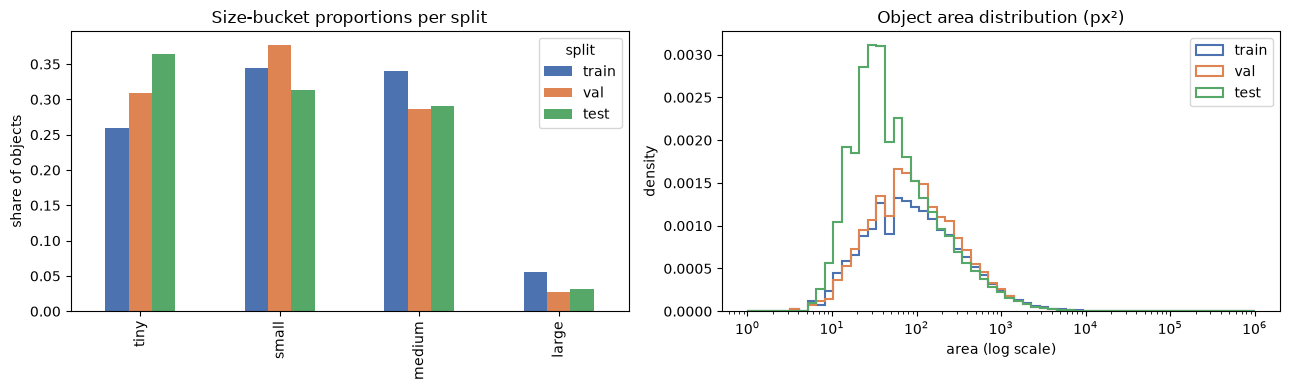

tiny (<16²) share per split: {'train': 0.2601, 'val': 0.3084, 'test': 0.3641}


In [7]:
bucket_counts = pd.crosstab(boxes["size_bucket"], boxes["split"]).reindex(SIZE_BUCKETS)[SPLITS]
bucket_share = bucket_counts / bucket_counts.sum(axis=0)
bucket_pooled = bucket_counts.sum(axis=1) / bucket_counts.values.sum()
display(bucket_counts)
display(bucket_share.round(4))

size_verdict = pd.DataFrame(
    {
        "size_TVD_vs_train": [tvd(bucket_share[s], bucket_share["train"]) for s in SPLITS],
        "size_TVD_vs_pooled": [tvd(bucket_share[s], bucket_pooled) for s in SPLITS],
    },
    index=SPLITS,
)
display(size_verdict.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bucket_share.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_title("Size-bucket proportions per split")
axes[0].set_ylabel("share of objects")
axes[0].set_xlabel("")

for split, color in zip(SPLITS, ["#4C72B0", "#DD8452", "#55A868"]):
    axes[1].hist(
        boxes.loc[boxes["split"] == split, "area"].clip(lower=1),
        bins=np.logspace(0, 6, 60),
        histtype="step",
        linewidth=1.5,
        label=split,
        color=color,
        density=True,
    )
axes[1].set_xscale("log")
axes[1].set_title("Object area distribution (px²)")
axes[1].set_xlabel("area (log scale)")
axes[1].set_ylabel("density")
axes[1].legend()
plt.tight_layout()
plt.show()

print("tiny (<16²) share per split:", bucket_share.loc["tiny"].round(4).to_dict())

## 5. Objects per image


,count,mean,median,std,min,max
split,,,,,,
train,6471,53.04,42.0,43.84,1,902
val,548,70.73,65.0,46.00,1,317
test,1610,46.65,36.0,44.05,1,461


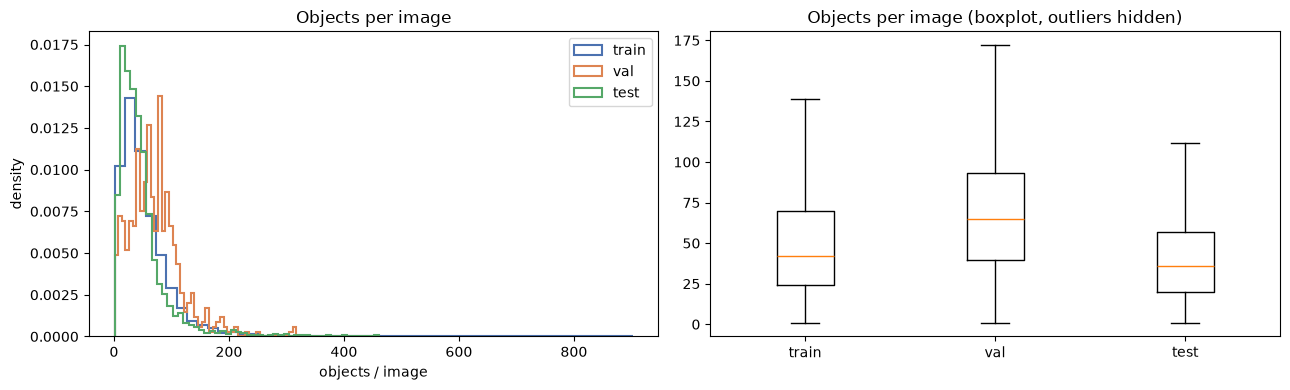

In [8]:
per_image = boxes.groupby(["split", "image"]).size().rename("objects").reset_index()
per_image_stats = (
    per_image.groupby("split")["objects"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reindex(SPLITS)
)
display(per_image_stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for split, color in zip(SPLITS, ["#4C72B0", "#DD8452", "#55A868"]):
    axes[0].hist(
        per_image.loc[per_image["split"] == split, "objects"],
        bins=50,
        histtype="step",
        linewidth=1.5,
        label=split,
        color=color,
        density=True,
    )
axes[0].set_title("Objects per image")
axes[0].set_xlabel("objects / image")
axes[0].set_ylabel("density")
axes[0].legend()
axes[1].boxplot(
    [per_image.loc[per_image["split"] == s, "objects"] for s in SPLITS],
    tick_labels=SPLITS,
    showfliers=False,
)
axes[1].set_title("Objects per image (boxplot, outliers hidden)")
plt.tight_layout()
plt.show()

## 6. Look at some photos

Ground-truth boxes are colour-coded by class; red dashed boxes are
ignored / don't-care regions.


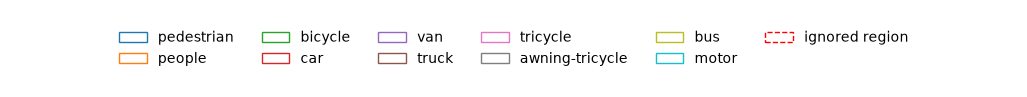

In [9]:
def draw_boxes(ax, split: str, name: str) -> None:
    """Draw one image with GT boxes (colour by class) and ignored regions."""
    img = Image.open(IMAGES_DIR / split / name).convert("RGB")
    width, height = img.size
    ax.imshow(img)
    label_path = LABELS_DIR / split / f"{Path(name).stem}.txt"
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            cls_id = int(parts[0])
            xc, yc, bw, bh = (float(v) for v in parts[1:])
            ax.add_patch(
                mpatches.Rectangle(
                    ((xc - bw / 2) * width, (yc - bh / 2) * height),
                    bw * width,
                    bh * height,
                    fill=False,
                    edgecolor=COLOR_BY_CLASS[cls_id],
                    linewidth=1.0,
                )
            )
    ignore_path = IGNORE_DIR / split / f"{Path(name).stem}.txt"
    if ignore_path.exists():
        for line in ignore_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            x1, y1, x2, y2 = (float(v) for v in parts[:4])
            ax.add_patch(
                mpatches.Rectangle(
                    (x1, y1),
                    x2 - x1,
                    y2 - y1,
                    fill=False,
                    edgecolor="red",
                    linewidth=0.8,
                    linestyle="--",
                )
            )
    n = manifests[split].loc[manifests[split]["image"] == name, "n_boxes"].iloc[0]
    ax.set_title(f"{split}/{name}  ({int(n)} boxes)", fontsize=7)
    ax.axis("off")


handles = [
    mpatches.Patch(edgecolor=COLOR_BY_CLASS[i], facecolor="none", label=CLASSES[i])
    for i in range(len(CLASSES))
] + [mpatches.Patch(edgecolor="red", facecolor="none", linestyle="--", label="ignored region")]
fig, ax = plt.subplots(figsize=(13, 1))
ax.legend(handles=handles, ncol=6, loc="center", frameon=False)
ax.axis("off")
plt.show()

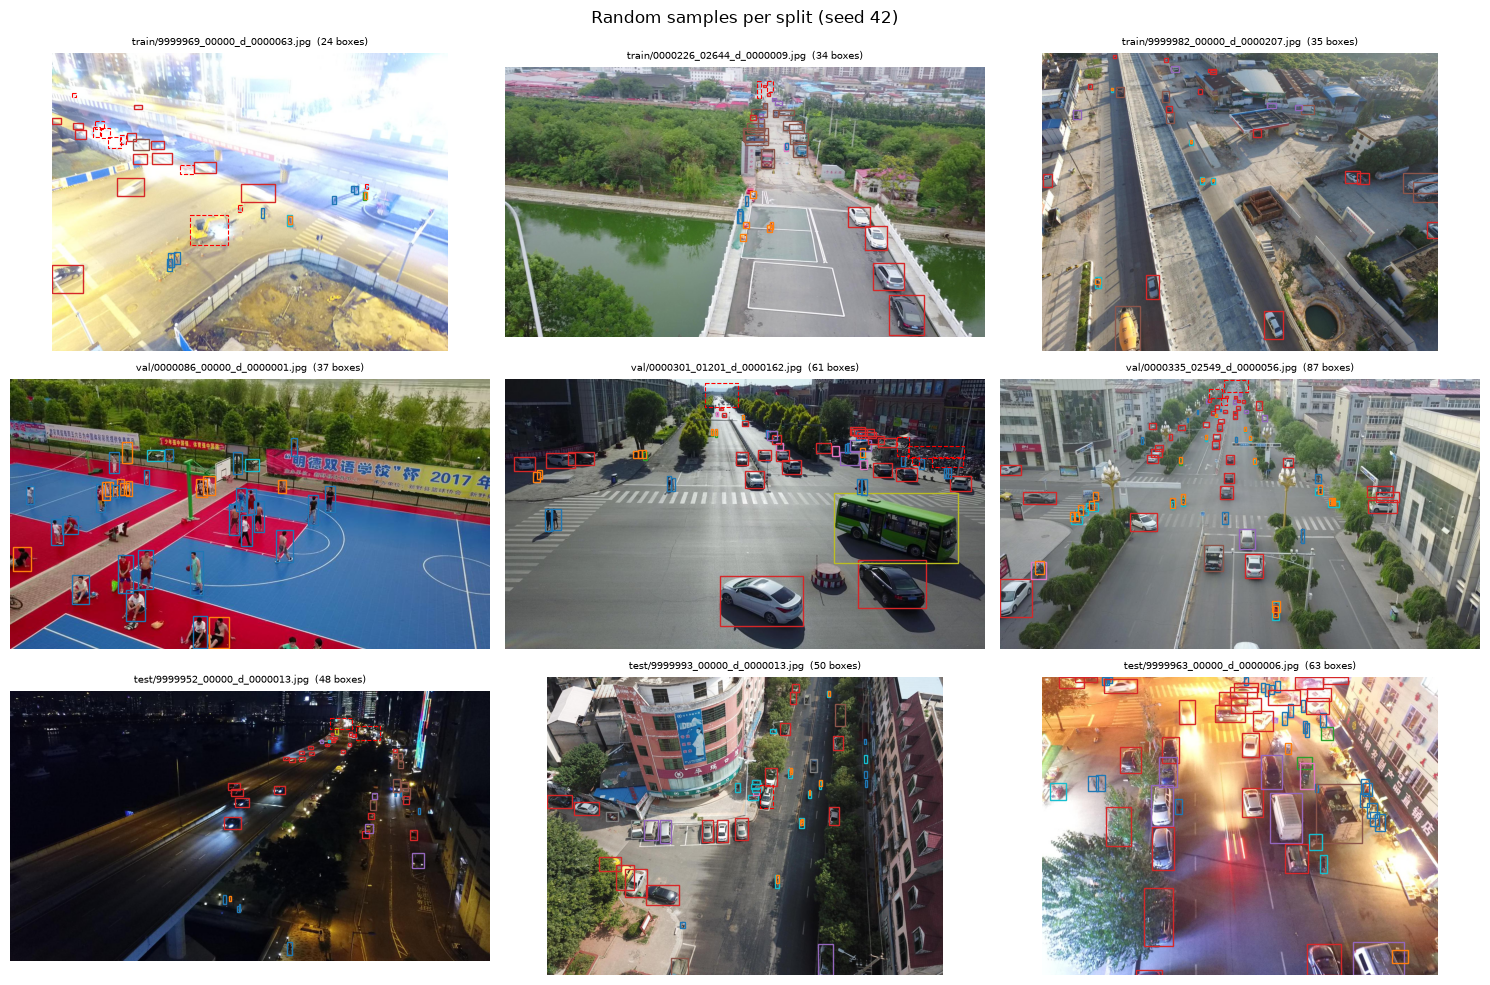

In [10]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(SPLITS), 3, figsize=(15, 3 * len(SPLITS) + 1))
for row, split in enumerate(SPLITS):
    names = manifests[split]["image"].to_numpy()
    picks = rng.choice(names, size=min(3, len(names)), replace=False)
    for col, name in enumerate(picks):
        draw_boxes(axes[row, col], split, name)
    axes[row, 0].set_ylabel(split, fontsize=12)
plt.suptitle("Random samples per split (seed 42)")
plt.tight_layout()
plt.show()

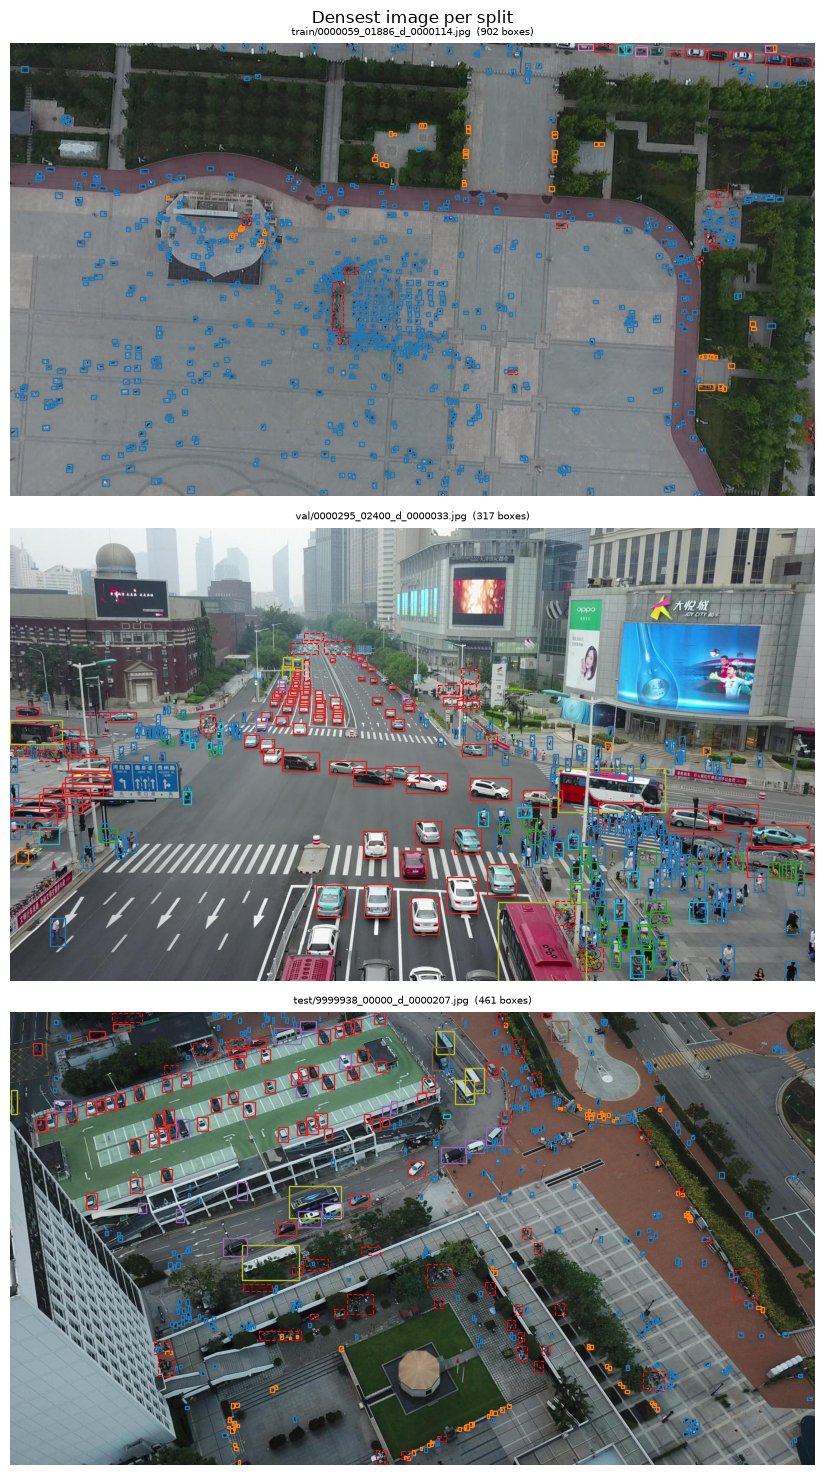

In [10]:
fig, axes = plt.subplots(len(SPLITS), 1, figsize=(15, 5 * len(SPLITS)))
for row, split in enumerate(SPLITS):
    densest = manifests[split].sort_values("n_boxes", ascending=False)["image"].iloc[0]
    draw_boxes(axes[row], split, densest)
plt.suptitle("Densest image per split")
plt.tight_layout()
plt.show()

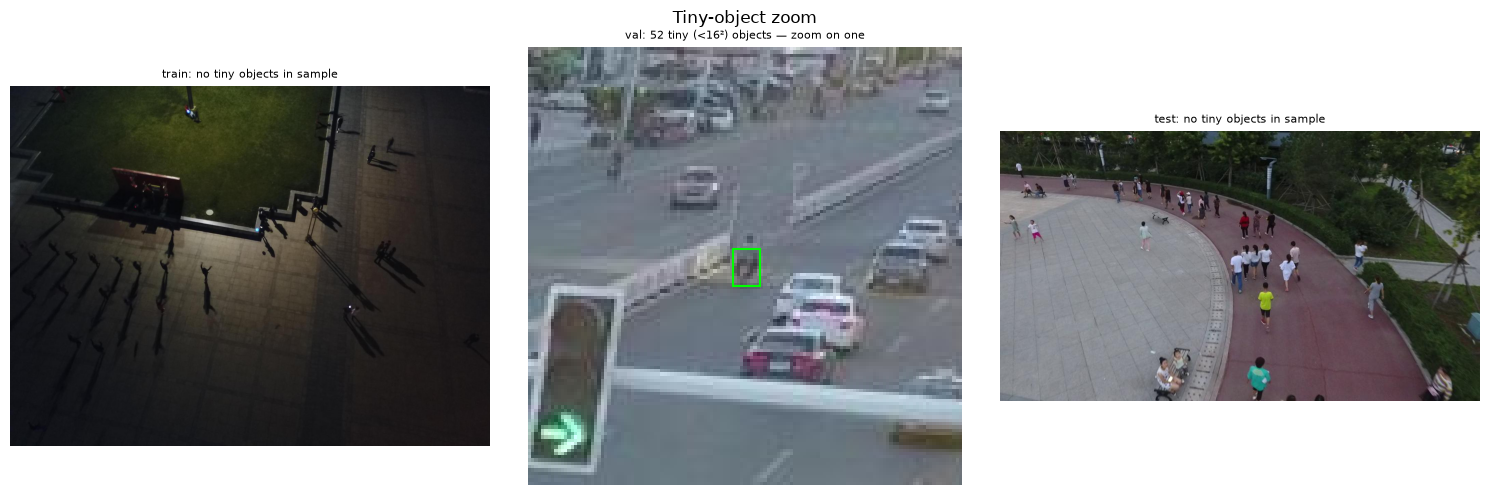

,share_tiny (<16²)
split,
train,0.2601
val,0.3084
test,0.3641


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, split in zip(axes, SPLITS):
    random_row = manifests[split].sample(1, random_state=42).iloc[0]
    name = random_row["image"]
    img = Image.open(IMAGES_DIR / split / name).convert("RGB")
    width, height = img.size
    label_path = LABELS_DIR / split / f"{Path(name).stem}.txt"
    tiny, boxes_px = [], []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            xc, yc, bw, bh = (float(v) for v in parts[1:])
            x1, y1 = (xc - bw / 2) * width, (yc - bh / 2) * height
            w_px, h_px = bw * width, bh * height
            boxes_px.append((x1, y1, w_px, h_px))
            if w_px * h_px < TINY_AREA:
                tiny.append((x1, y1, w_px, h_px))
    if not tiny:
        ax.imshow(img)
        ax.set_title(f"{split}: no tiny objects in sample", fontsize=8)
        ax.axis("off")
        continue
    x1, y1, w_px, h_px = tiny[len(tiny) // 2]
    cx, cy = x1 + w_px / 2, y1 + h_px / 2
    half = max(48, 6 * max(w_px, h_px))
    xa, ya = int(max(0, cx - half)), int(max(0, cy - half))
    xb, yb = int(min(width, cx + half)), int(min(height, cy + half))
    crop = np.asarray(img)[ya:yb, xa:xb]
    ax.imshow(crop, extent=(xa, xb, yb, ya))
    ax.add_patch(
        mpatches.Rectangle((x1, y1), w_px, h_px, fill=False, edgecolor="lime", linewidth=1.5)
    )
    ax.set_title(f"{split}: {len(tiny)} tiny (<16²) objects — zoom on one", fontsize=8)
    ax.axis("off")
plt.suptitle("Tiny-object zoom")
plt.tight_layout()
plt.show()

tiny_share = boxes["size_bucket"].eq("tiny").groupby(boxes["split"]).mean().reindex(SPLITS)
display(tiny_share.rename("share_tiny (<16²)").round(4).to_frame())

## 7. Conclusions


## 7. Conclusions

**Are the splits stratified? Only approximately.** The official VisDrone splits
are fixed and were not balanced, and this EDA shows systematic differences from
the training mix (TVD: 0 = identical, 1 = disjoint).

- **Class mix.** `train` matches the pooled mix very closely (TVD ≈ 0.018).
  `test-dev` deviates moderately (TVD ≈ 0.081 vs train, 0.066 vs pooled), and `val` deviates
  most (**TVD ≈ 0.113 vs train**):
  - `val` is enriched in `people` (+5.3 pp) and `motor` (+4.0 pp) and depleted
    in `car` (−5.9 pp) relative to train;
  - `test-dev` is enriched in `pedestrian` (+4.9 pp) and `bus` (+2.2 pp) and
    depleted in `car` (−4.8 pp).
- **Object size.** `val` mildly differs from train (size TVD ≈ 0.081);
  `test-dev` differs more (≈ 0.104) and is clearly **tiny-heavy**: 36.4 % of its
  objects are < 16² px versus 26.0 % in train. Test-dev is therefore a harder,
  small-object-oriented benchmark, consistent with the lower test-dev scores in
  [docs/baseline_results.md](../docs/baseline_results.md).
- **Objects per image.** `val` is denser (70.7 objects/image) than train (53.0)
  and test-dev (46.7).

**Implications.**

- Do not compare absolute scores across splits. `val` is used **only** for
  checkpoint/hyperparameter selection; every reported score uses test-dev, as
  already adopted in the baseline.
- Part of any train→test gap reflects this distribution shift, not only model
  quality.
- Because test-dev is tiny-heavy, the tiny-object metrics are the most
  important and the most stringent part of the evaluation.

The photo overlays (section 6) match the statistics: dense scenes of tiny
vehicles and pedestrians with red ignored/don't-care regions that the evaluator
must respect.
